In [6]:
%pip install -e ..

Obtaining file:///Users/willaugustyn/LZ/dmtools_libraries
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for dmtools_libraries (pyproject.toml) ... done
  Created wheel for dmtools_libraries: filename=dmtools_libraries-0.1.0-0.editable-py3-none-any.whl size=2384 sha256=30e071fafa0de37127ce9f3728f8eb57aadb7da408119b2c55dd5f352119ecd6
  Stored in directory: /private/var/folders/_z/d_xkthvd31q71srl4sdw21jc0000gn/T/pip-ephem-wheel-cache-kix0xstb/wheels/a9/7d/ce/c6b035a42661b16261aaedfc64b94fed89dfb4b3ef176d7e0c
Successfully built dmtools_libraries
  Attempting uninstall: dmtools_libraries
    Found existing installation: dmtools_libraries 0.1.0
    Uninstalling dmtools_libraries-0.1.0:
      Successfully uninstalled dmtools_libraries-0.1.0

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To u

/Users/willaugustyn/LZ/dmtools_libraries/src/dmtools_libraries/render_core.py


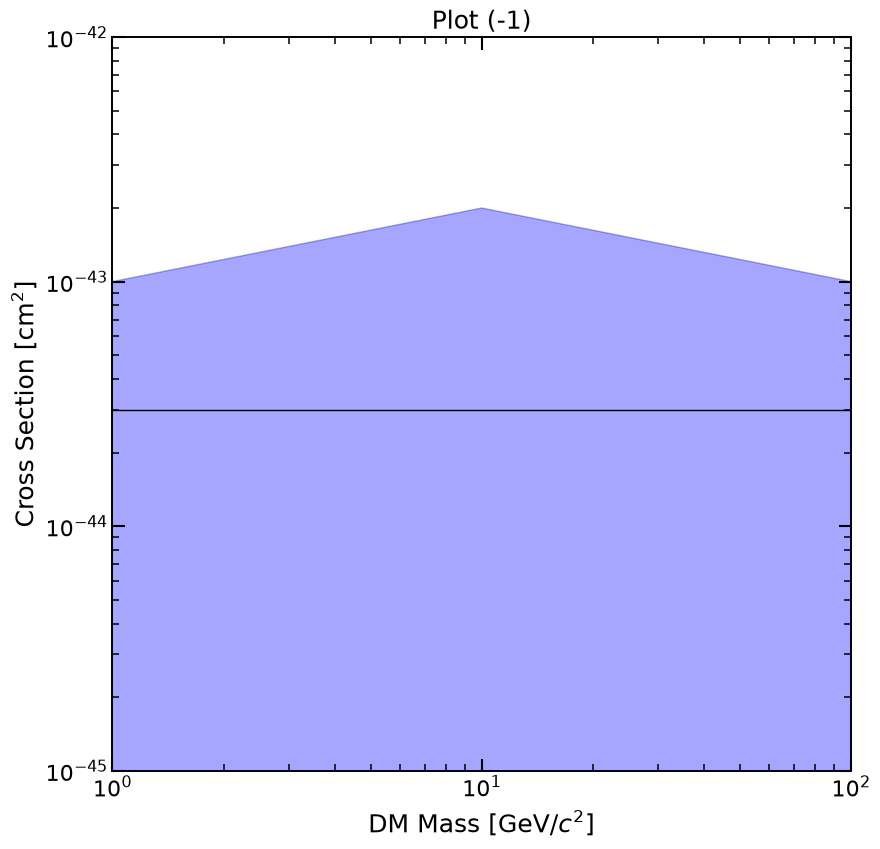

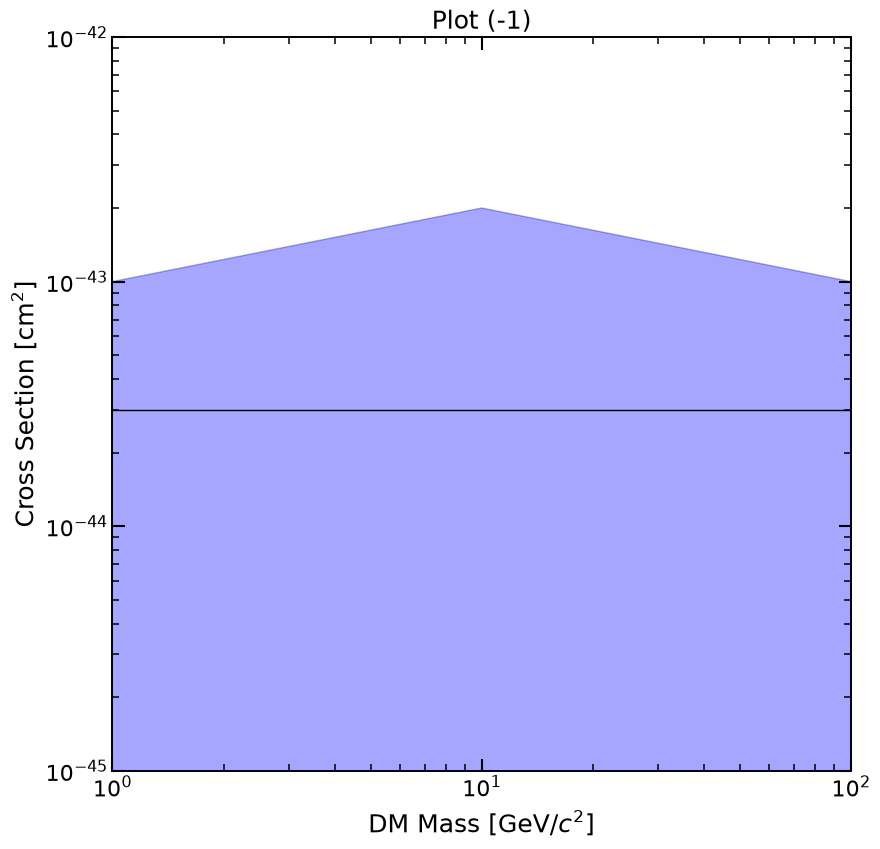

In [7]:
from IPython.display import display
from dmtools_libraries import render_core

print(render_core.__file__)  # Should point into this checkout's src/ directory.

displays = [
    {
        "properties": {"style": "line", "color": "black"},
        "data": [{"properties": {
            "values": [[[1, 3e-44], [10, 3e-44], [100, 3e-44]]]
        }}],
    },
    {
        "properties": {"style": "fill", "color": "blue"},
        "data": [{"properties": {
            "values": [[[1, 1e-43], [10, 2e-43], [100, 1e-43]]]
        }}],
    },
]

_, fig = await render_core.render_plot_core(
    plot_data={},
    plot_properties={"xMin": 1, "xMax": 100, "yMin": -45, "yMax": -42},
    display_data_list=displays,
    output_format="object",
)

ax = fig.axes[0]
assert len(ax.lines) == 1
assert len(ax.collections) == 1
display(fig)

In [9]:
from importlib import reload
from dmtools_libraries import render_core

reload(render_core)
print(render_core.__file__)
print(hasattr(render_core, "render_plot_core_V1"))  # Should print True.

/Users/willaugustyn/LZ/dmtools_libraries/src/dmtools_libraries/render_core.py
True


/Users/willaugustyn/LZ/dmtools_libraries/src/dmtools_libraries/render_core.py


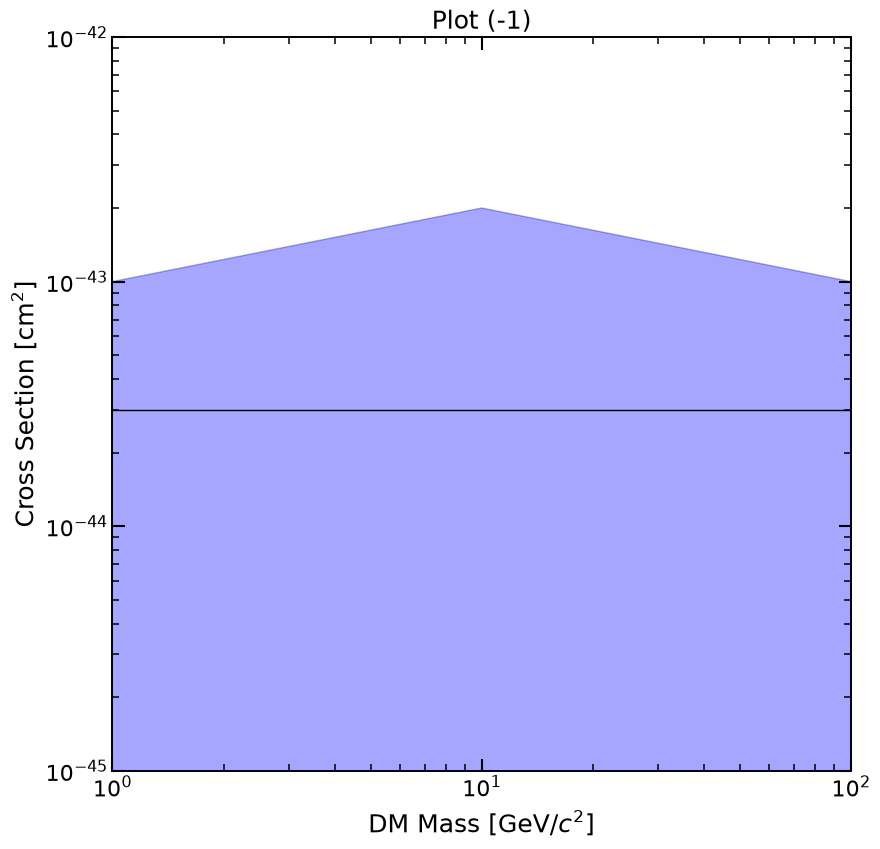

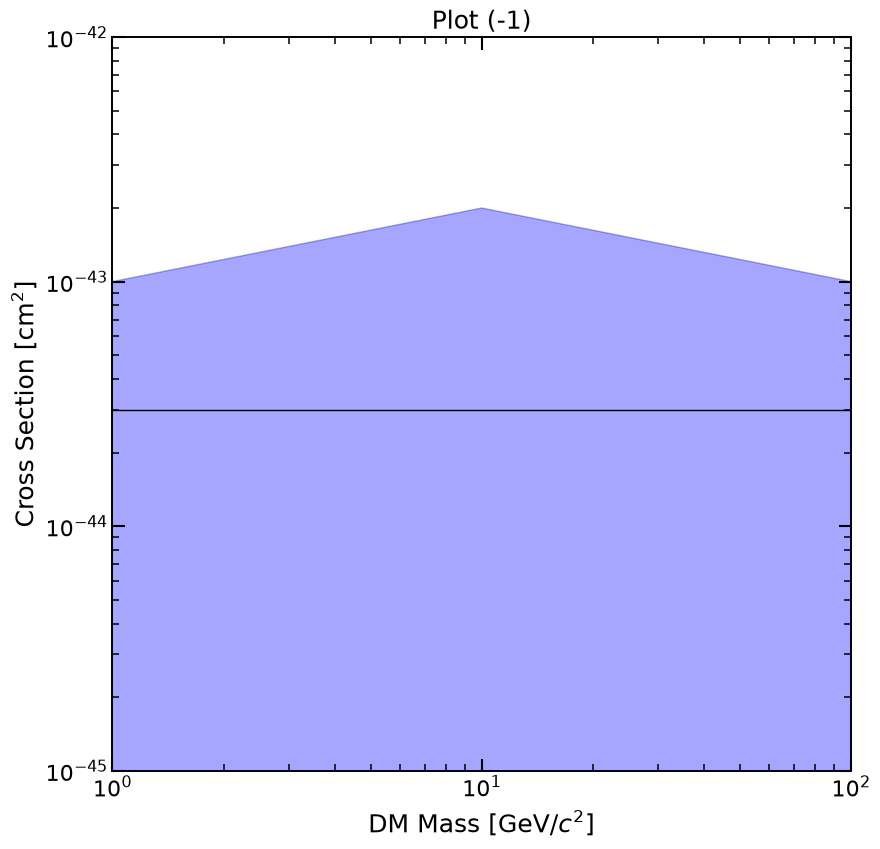

In [11]:
from IPython.display import display
from dmtools_libraries import render_core

print(render_core.__file__)  # Should point into this checkout's src/ directory.

displays = [
    {
        "properties": {"style": "line", "color": "black"},
        "data": [{"properties": {
            "values": [[[1, 3e-44], [10, 3e-44], [100, 3e-44]]]
        }}],
    },
    {
        "properties": {"style": "fill", "color": "blue"},
        "data": [{"properties": {
            "values": [[[1, 1e-43], [10, 2e-43], [100, 1e-43]]]
        }}],
    },
]

_, fig = await render_core.render_plot_core_V1(
    plot_data={},
    plot_properties={"xMin": 1, "xMax": 100, "yMin": -45, "yMax": -42},
    display_data_list=displays,
    output_format="object",
)

ax = fig.axes[0]
display(fig)

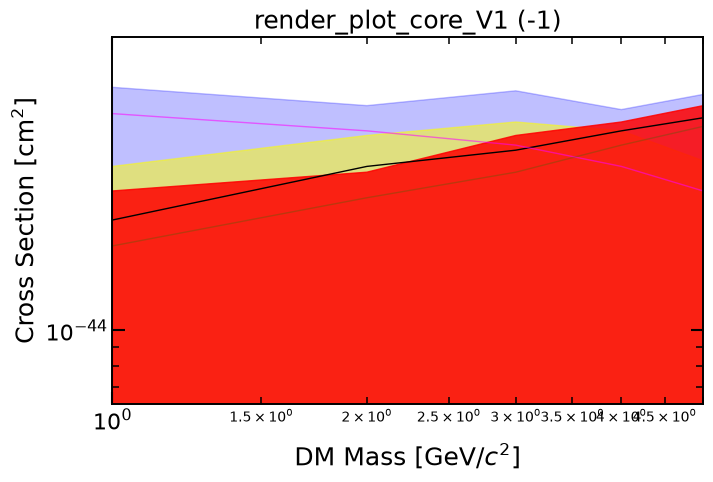

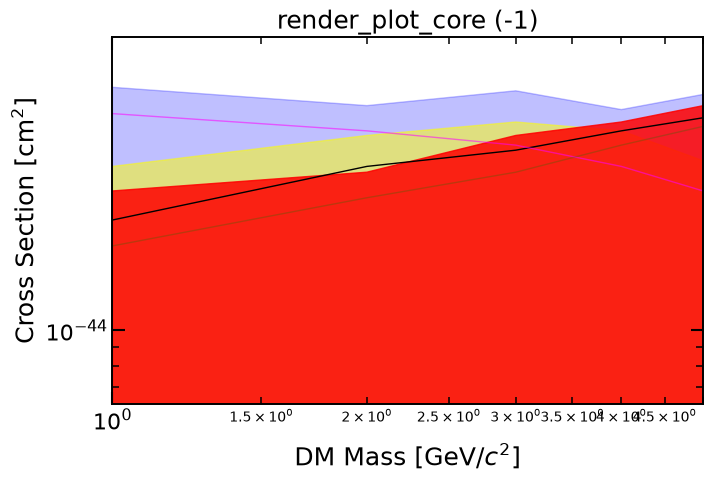

In [14]:
from importlib import reload
from unittest.mock import patch

import matplotlib.pyplot as plt
from IPython.display import display
from dmtools_libraries import render_core

reload(render_core)

x = [1, 2, 3, 4, 5]
layers = [
    ("line", "black",  1.00, [2.0, 2.8, 3.1, 3.5, 3.8]),
    ("fill", "blue",   0.25, [4.6, 4.1, 4.5, 4.0, 4.4]),
    ("line", "magenta", 0.55, [3.9, 3.5, 3.2, 2.8, 2.4]),
    ("fill", "yellow", 0.50, [2.8, 3.4, 3.7, 3.5, 2.9]),
    ("line", "green",  0.25, [1.7, 2.3, 2.7, 3.2, 3.6]),
    ("fill", "red",    0.85, [2.4, 2.7, 3.4, 3.7, 4.1]),
]

displays = [
    {
        "properties": {"style": style, "color": color},
        "data": [{"properties": {
            "values": [[[mass, value * 1e-44] for mass, value in zip(x, y)]]
        }}],
    }
    for style, color, _, y in layers
]

opacity = {(style, color): alpha for style, color, alpha, _ in layers}
original_style = render_core.get_canonical_style_mpl

def style_with_opacity(color, style):
    kwargs = original_style(color, style)
    return {**kwargs, "alpha": opacity[(style, color)]}

with patch.object(render_core, "get_canonical_style_mpl", style_with_opacity):
    for render in (render_core.render_plot_core_V1, render_core.render_plot_core):
        _, fig = await render(
            plot_data={},
            plot_properties={
                "name": render.__name__,
                "xMin": 1, "xMax": 5,
                "yMin": -44.2, "yMax": -43.2,
            },
            display_data_list=displays,
            figsize=(8, 5),
            output_format="object",
        )

        ax = fig.axes[0]
        visible_lines = [
            line for line in ax.lines
            if line.get_linewidth() > 0
        ]
        assert len(visible_lines) == len(ax.collections) == 3
        assert min(line.get_zorder() for line in visible_lines) > max(
            fill.get_zorder() for fill in ax.collections
        )

        display(fig)
        plt.close(fig)